<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/10_analisis_kesalahan_dan_kesimpulan_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:

from google.colab import drive
drive.mount('/content/drive')

print("GOOGLE DRIVE BERHASIL TERHUBUNG")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GOOGLE DRIVE BERHASIL TERHUBUNG


In [23]:

import os
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("SEMUA LIBRARY BERHASIL DIMUAT")


SEMUA LIBRARY BERHASIL DIMUAT


In [24]:

DATASET_DIR = (
    "/content/drive/.shortcut-targets-by-id/"
    "1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/"
    "COMPUTER VISION_TI 2026/kelompok 3/"
    "KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"
)

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

DATASET_FILE = os.path.join(OUTPUT_DIR, "dataset_split.npz")

HOG_FILE = os.path.join(OUTPUT_DIR, "model_hog_svm.pkl")
CNN_FILE = os.path.join(OUTPUT_DIR, "model_cnn_baseline.keras")
IMPROVED_FILE = os.path.join(OUTPUT_DIR, "model_cnn_improved.keras")

HASIL_DIR = os.path.join(OUTPUT_DIR, "HASIL_ANALISIS_NOTEBOOK_10")
os.makedirs(HASIL_DIR, exist_ok=True)

print("LOKASI DATASET:", DATASET_FILE)
print("LOKASI OUTPUT:", OUTPUT_DIR)

for file in [DATASET_FILE, HOG_FILE, CNN_FILE, IMPROVED_FILE]:
    print(
        os.path.basename(file),
        "BERHASIL DITEMUKAN" if os.path.exists(file) else "TIDAK DITEMUKAN"
    )

assert all(os.path.exists(f) for f in [
    DATASET_FILE, HOG_FILE, CNN_FILE, IMPROVED_FILE
]), "Ada file yang belum ditemukan. Periksa lokasi Google Drive."


LOKASI DATASET: /content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/dataset_split.npz
LOKASI OUTPUT: /content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN
dataset_split.npz BERHASIL DITEMUKAN
model_hog_svm.pkl BERHASIL DITEMUKAN
model_cnn_baseline.keras BERHASIL DITEMUKAN
model_cnn_improved.keras BERHASIL DITEMUKAN


In [25]:

data = np.load(DATASET_FILE, allow_pickle=True)

X_test = data["X_test"]
y_test = data["y_test"]
k_test = data["k_test"]

KELAS = ["TAS", "BUKU GAMBAR", "LAPTOP"]

# Mengubah label one-hot menjadi angka kelas jika diperlukan
if y_test.ndim > 1 and y_test.shape[-1] == 3:
    y_test = np.argmax(y_test, axis=1)
else:
    y_test = y_test.astype(int).reshape(-1)

# Normalisasi gambar untuk CNN
X_cnn = X_test.astype("float32")

if X_cnn.max() > 1:
    X_cnn = X_cnn / 255.0

print("DATA TESTING BERHASIL DIBACA")
print("Jumlah testing:", len(X_test))
print("Ukuran gambar:", X_test.shape)
print("Jumlah kelas:", len(KELAS))
print("Kondisi testing:", np.unique(k_test, return_counts=True))


DATA TESTING BERHASIL DIBACA
Jumlah testing: 18
Ukuran gambar: (18, 128, 128, 3)
Jumlah kelas: 3
Kondisi testing: (array(['KONDISI IDEAL', 'KONDISI SULIT'], dtype='<U13'), array([9, 9]))


In [26]:

import tensorflow as tf

model_hog_svm = joblib.load(HOG_FILE)
model_cnn = tf.keras.models.load_model(CNN_FILE)
model_improved = tf.keras.models.load_model(IMPROVED_FILE)

print("MODEL HOG + SVM BERHASIL DIMUAT")
print("MODEL CNN BASELINE BERHASIL DIMUAT")
print("MODEL CNN IMPROVED BERHASIL DIMUAT")


MODEL HOG + SVM BERHASIL DIMUAT
MODEL CNN BASELINE BERHASIL DIMUAT
MODEL CNN IMPROVED BERHASIL DIMUAT


In [27]:

# Prediksi CNN Baseline
prediksi_prob = model_cnn.predict(X_cnn, verbose=0)
pred_cnn = np.argmax(prediksi_prob, axis=1)

# Prediksi CNN Improved
prediksi_improved = model_improved.predict(X_cnn, verbose=0)
pred_improved = np.argmax(prediksi_improved, axis=1)

print("PREDIKSI CNN BASELINE BERHASIL")
print("PREDIKSI CNN IMPROVED BERHASIL")

# Mencari jumlah fitur yang diharapkan model SVM
def jumlah_fitur_model(model):
    if hasattr(model, "n_features_in_"):
        return model.n_features_in_

    if hasattr(model, "steps"):
        for _, step in reversed(model.steps):
            if hasattr(step, "n_features_in_"):
                return step.n_features_in_

    return None

jumlah_fitur = jumlah_fitur_model(model_hog_svm)

print("Jumlah fitur model HOG + SVM:", jumlah_fitur)

# Membuat fitur HOG grayscale
def ekstraksi_hog(gambar):
    hasil = []

    for img in gambar:
        if img.max() <= 1:
            img = img * 255

        img = np.clip(img, 0, 255).astype("uint8")

        if img.ndim == 3:
            img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        img = cv2.resize(img, (128, 128))

        fitur = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        hasil.append(fitur)

    return np.array(hasil)

X_hog = ekstraksi_hog(X_test)

if jumlah_fitur is not None and X_hog.shape[1] != jumlah_fitur:
    raise ValueError(
        f"Dimensi HOG tidak cocok: hasil ekstraksi {X_hog.shape[1]}, "
        f"model membutuhkan {jumlah_fitur}. "
        "Gunakan konfigurasi ekstraksi yang sama persis dengan Notebook training."
    )

pred_test = model_hog_svm.predict(X_hog)

# Menyamakan format label
pred_test = np.asarray(pred_test).astype(int).reshape(-1)

print("PREDIKSI HOG + SVM BERHASIL")

print("\nSEMUA PREDIKSI SELESAI")
print("HOG + SVM:", len(pred_test))
print("CNN Baseline:", len(pred_cnn))
print("CNN Improved:", len(pred_improved))


PREDIKSI CNN BASELINE BERHASIL
PREDIKSI CNN IMPROVED BERHASIL
Jumlah fitur model HOG + SVM: 8100
PREDIKSI HOG + SVM BERHASIL

SEMUA PREDIKSI SELESAI
HOG + SVM: 18
CNN Baseline: 18
CNN Improved: 18


In [28]:

hasil_prediksi = {
    "HOG + SVM": pred_test,
    "CNN Baseline": pred_cnn,
    "CNN Improved": pred_improved
}

hasil_akurasi = []

for nama, prediksi in hasil_prediksi.items():
    benar = int(np.sum(y_test == prediksi))
    salah = int(len(y_test) - benar)
    akurasi = accuracy_score(y_test, prediksi) * 100

    hasil_akurasi.append({
        "Metode": nama,
        "Akurasi (%)": round(akurasi, 2),
        "Prediksi Benar": benar,
        "Prediksi Salah": salah
    })

tabel_akurasi = pd.DataFrame(hasil_akurasi)

print("TABEL PERBANDINGAN AKURASI")
display(tabel_akurasi)

tabel_akurasi.to_csv(
    os.path.join(HASIL_DIR, "perbandingan_akurasi.csv"),
    index=False
)


TABEL PERBANDINGAN AKURASI


,Metode,Akurasi (%),Prediksi Benar,Prediksi Salah
0,HOG + SVM,77.78,14,4
1,CNN Baseline,72.22,13,5
2,CNN Improved,50.00,9,9


In [29]:

for nama, prediksi in hasil_prediksi.items():

    print("\n" + "=" * 65)
    print("CLASSIFICATION REPORT:", nama)
    print("=" * 65)

    print(classification_report(
        y_test,
        prediksi,
        labels=[0, 1, 2],
        target_names=KELAS,
        zero_division=0
    ))



CLASSIFICATION REPORT: HOG + SVM
              precision    recall  f1-score   support

         TAS       1.00      0.67      0.80         6
 BUKU GAMBAR       0.60      1.00      0.75         6
      LAPTOP       1.00      0.67      0.80         6

    accuracy                           0.78        18
   macro avg       0.87      0.78      0.78        18
weighted avg       0.87      0.78      0.78        18


CLASSIFICATION REPORT: CNN Baseline
              precision    recall  f1-score   support

         TAS       0.62      0.83      0.71         6
 BUKU GAMBAR       0.75      1.00      0.86         6
      LAPTOP       1.00      0.33      0.50         6

    accuracy                           0.72        18
   macro avg       0.79      0.72      0.69        18
weighted avg       0.79      0.72      0.69        18


CLASSIFICATION REPORT: CNN Improved
              precision    recall  f1-score   support

         TAS       0.44      0.67      0.53         6
 BUKU GAMBAR       0.

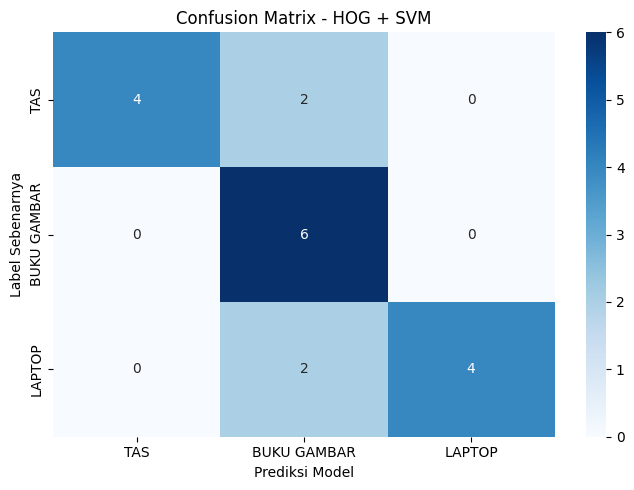

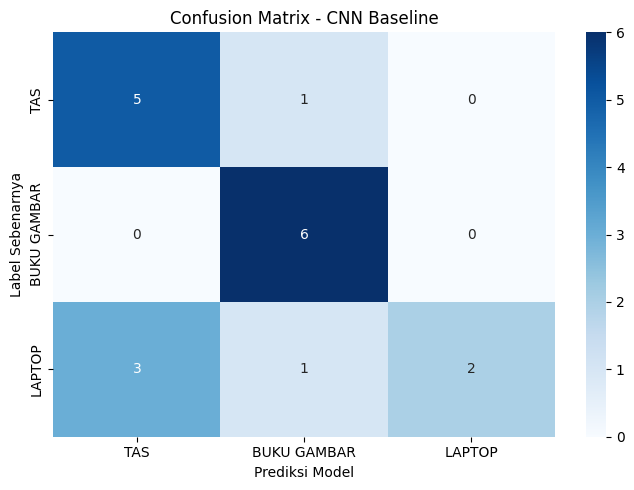

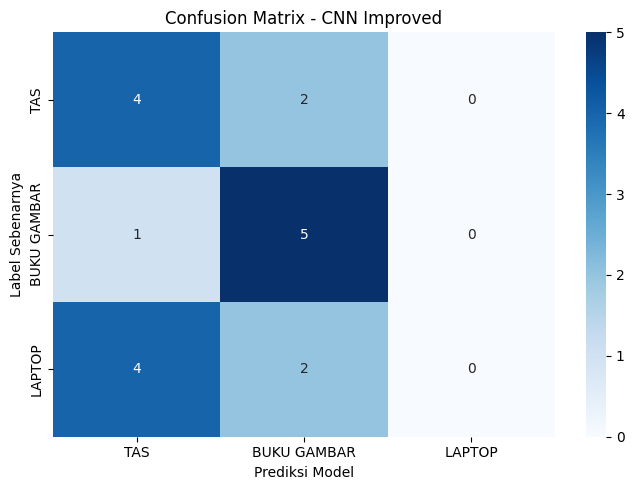

In [30]:

for nama, prediksi in hasil_prediksi.items():

    cm = confusion_matrix(
        y_test,
        prediksi,
        labels=[0, 1, 2]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=KELAS,
        yticklabels=KELAS
    )

    plt.title("Confusion Matrix - " + nama)
    plt.xlabel("Prediksi Model")
    plt.ylabel("Label Sebenarnya")
    plt.tight_layout()
    plt.show()

    np.savetxt(
        os.path.join(
            HASIL_DIR,
            "confusion_matrix_" + nama.lower().replace(" ", "_").replace("+", "dan") + ".csv"
        ),
        cm,
        delimiter=",",
        fmt="%d"
    )


In [31]:

kondisi = np.array([
    str(k).strip().lower() for k in k_test
])

mask_ideal = np.array([
    "ideal" in k for k in kondisi
])

mask_sulit = np.array([
    "sulit" in k for k in kondisi
])

print("Jumlah kondisi ideal:", mask_ideal.sum())
print("Jumlah kondisi sulit:", mask_sulit.sum())

assert mask_ideal.sum() == 9, "Jumlah data ideal tidak sesuai."
assert mask_sulit.sum() == 9, "Jumlah data sulit tidak sesuai."

hasil_kondisi = []

for nama, prediksi in hasil_prediksi.items():

    akurasi_ideal = accuracy_score(
        y_test[mask_ideal],
        prediksi[mask_ideal]
    ) * 100

    akurasi_sulit = accuracy_score(
        y_test[mask_sulit],
        prediksi[mask_sulit]
    ) * 100

    hasil_kondisi.append({
        "Metode": nama,
        "Ideal (%)": round(akurasi_ideal, 2),
        "Sulit (%)": round(akurasi_sulit, 2)
    })

tabel_kondisi = pd.DataFrame(hasil_kondisi)

print("\nPERBANDINGAN KONDISI IDEAL DAN SULIT")
display(tabel_kondisi)

tabel_kondisi.to_csv(
    os.path.join(HASIL_DIR, "perbandingan_kondisi.csv"),
    index=False
)


Jumlah kondisi ideal: 9
Jumlah kondisi sulit: 9

PERBANDINGAN KONDISI IDEAL DAN SULIT


,Metode,Ideal (%),Sulit (%)
0,HOG + SVM,77.78,77.78
1,CNN Baseline,66.67,77.78
2,CNN Improved,44.44,55.56


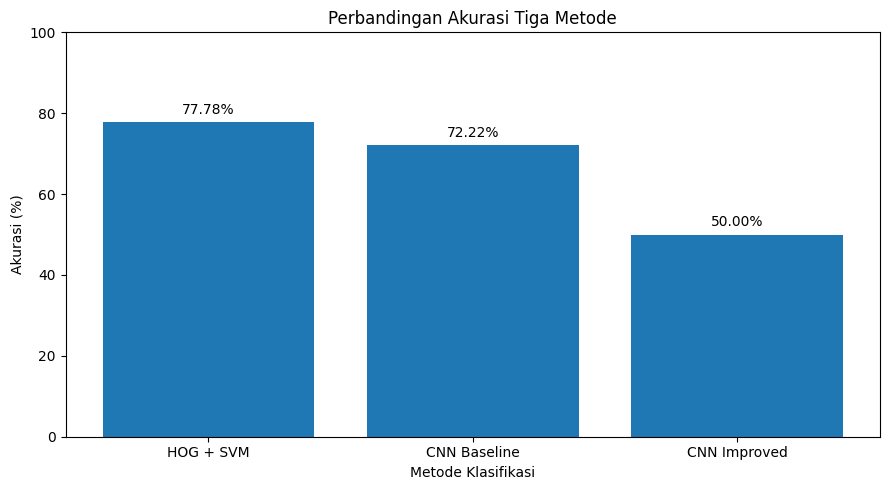

In [32]:

plt.figure(figsize=(9, 5))

plt.bar(
    tabel_akurasi["Metode"],
    tabel_akurasi["Akurasi (%)"]
)

plt.title("Perbandingan Akurasi Tiga Metode")
plt.xlabel("Metode Klasifikasi")
plt.ylabel("Akurasi (%)")
plt.ylim(0, 100)

for i, nilai in enumerate(tabel_akurasi["Akurasi (%)"]):
    plt.text(i, nilai + 2, f"{nilai:.2f}%", ha="center")

plt.tight_layout()
plt.show()


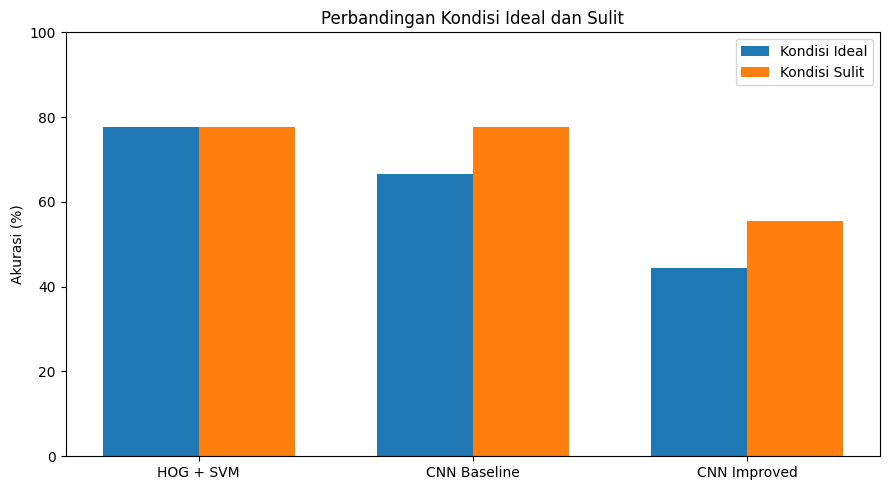

In [33]:

x = np.arange(len(tabel_kondisi))
lebar = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - lebar/2,
    tabel_kondisi["Ideal (%)"],
    lebar,
    label="Kondisi Ideal"
)

plt.bar(
    x + lebar/2,
    tabel_kondisi["Sulit (%)"],
    lebar,
    label="Kondisi Sulit"
)

plt.xticks(x, tabel_kondisi["Metode"])
plt.ylabel("Akurasi (%)")
plt.title("Perbandingan Kondisi Ideal dan Sulit")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()



KESALAHAN KLASIFIKASI: HOG + SVM
Jumlah gambar salah: 4


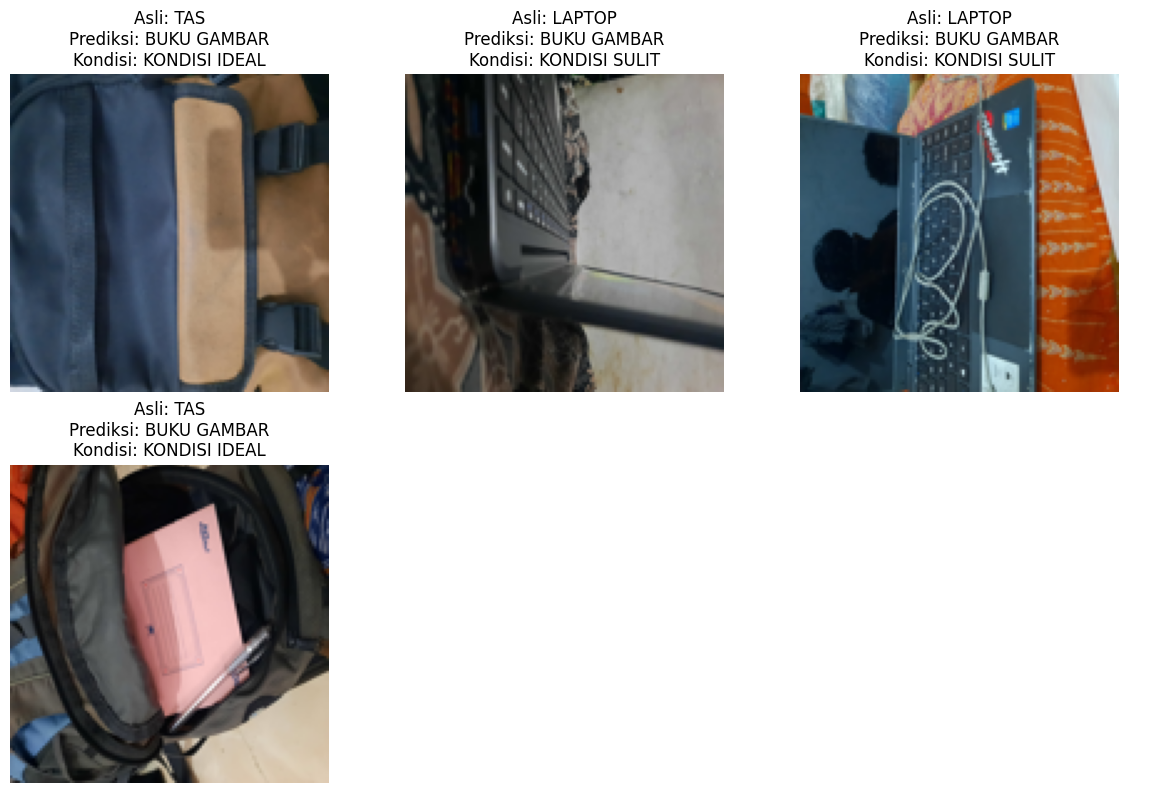


KESALAHAN KLASIFIKASI: CNN Baseline
Jumlah gambar salah: 5


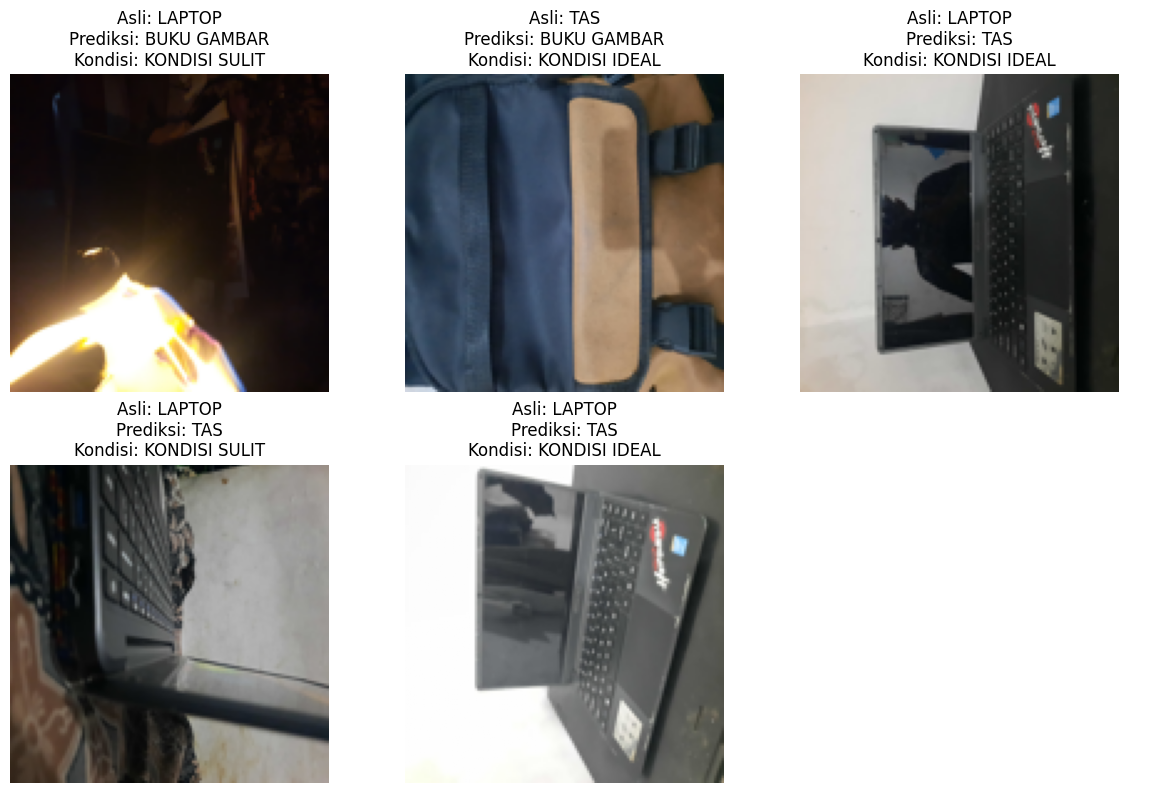


KESALAHAN KLASIFIKASI: CNN Improved
Jumlah gambar salah: 9


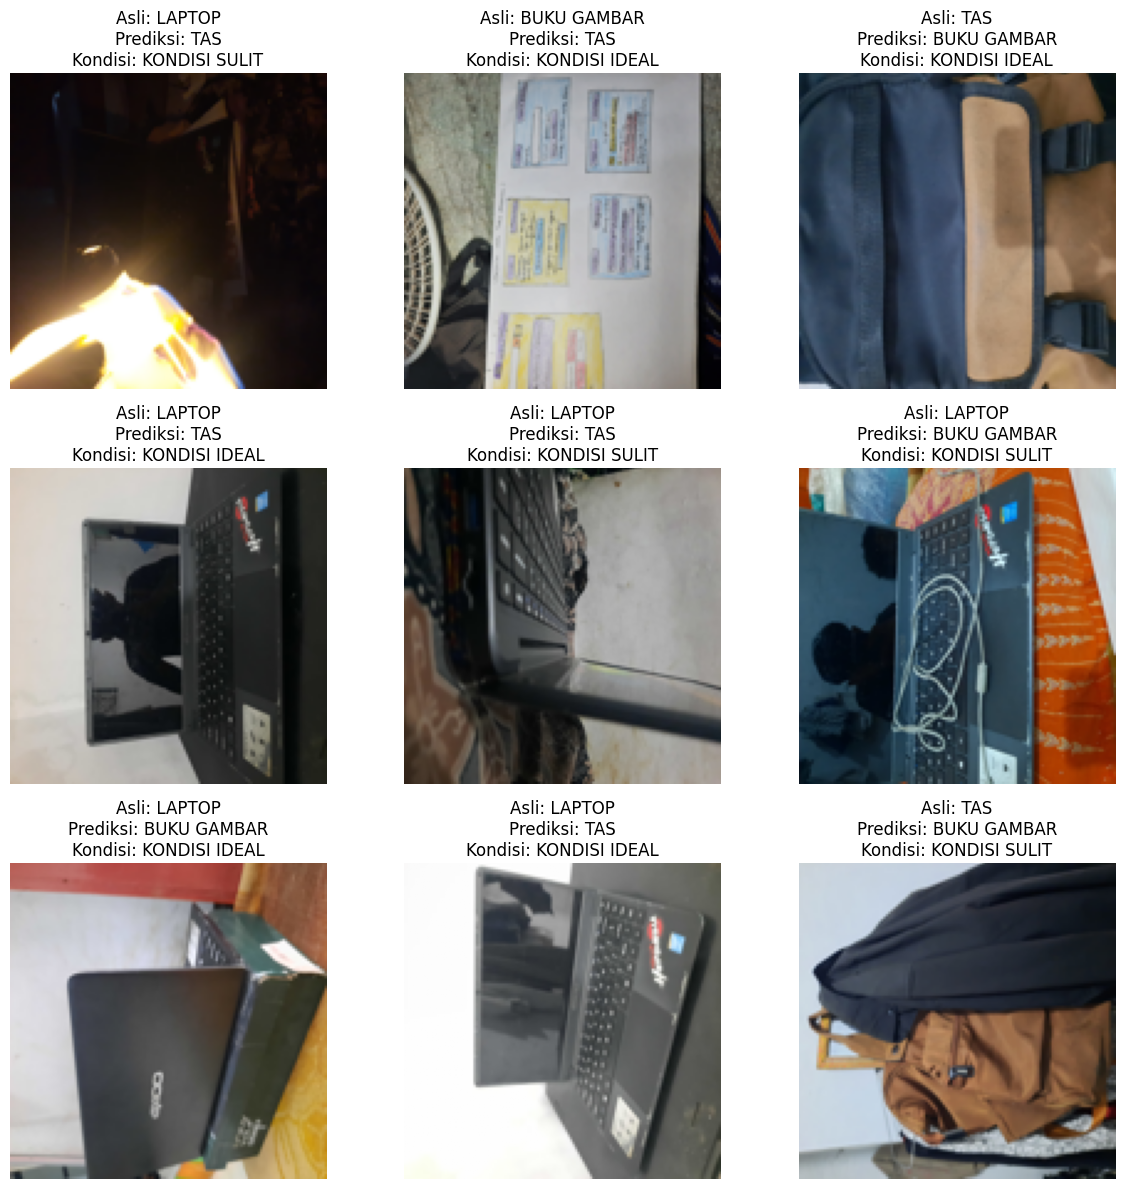

In [34]:

for nama, prediksi in hasil_prediksi.items():

    salah = np.where(y_test != prediksi)[0]

    print("\n" + "=" * 60)
    print("KESALAHAN KLASIFIKASI:", nama)
    print("Jumlah gambar salah:", len(salah))
    print("=" * 60)

    if len(salah) == 0:
        print("Tidak ada gambar yang salah diklasifikasikan.")
        continue

    jumlah_tampil = min(len(salah), 12)

    fig, axes = plt.subplots(
        int(np.ceil(jumlah_tampil / 3)),
        3,
        figsize=(12, 4 * int(np.ceil(jumlah_tampil / 3)))
    )

    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, salah[:jumlah_tampil]):

        gambar = X_test[idx]

        if gambar.max() > 1:
            gambar = gambar / 255.0

        ax.imshow(np.clip(gambar, 0, 1))
        ax.set_title(
            f"Asli: {KELAS[y_test[idx]]}\n"
            f"Prediksi: {KELAS[prediksi[idx]]}\n"
            f"Kondisi: {k_test[idx]}"
        )
        ax.axis("off")

    for ax in axes[jumlah_tampil:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [35]:

data_kesalahan = []

for nama, prediksi in hasil_prediksi.items():

    for i in range(len(y_test)):

        if y_test[i] != prediksi[i]:

            data_kesalahan.append({
                "Metode": nama,
                "Nomor Gambar": i + 1,
                "Label Sebenarnya": KELAS[y_test[i]],
                "Hasil Prediksi": KELAS[prediksi[i]],
                "Kondisi": str(k_test[i])
            })

df_kesalahan = pd.DataFrame(data_kesalahan)

print("DAFTAR GAMBAR YANG SALAH DIKLASIFIKASIKAN")
display(df_kesalahan)

df_kesalahan.to_csv(
    os.path.join(HASIL_DIR, "daftar_kesalahan_prediksi.csv"),
    index=False
)


DAFTAR GAMBAR YANG SALAH DIKLASIFIKASIKAN


,Metode,Nomor Gambar,Label Sebenarnya,Hasil Prediksi,Kondisi
0,HOG + SVM,6,TAS,BUKU GAMBAR,KONDISI IDEAL
1,HOG + SVM,10,LAPTOP,BUKU GAMBAR,KONDISI SULIT
2,HOG + SVM,11,LAPTOP,BUKU GAMBAR,KONDISI SULIT
3,HOG + SVM,16,TAS,BUKU GAMBAR,KONDISI IDEAL
4,CNN Baseline,1,LAPTOP,BUKU GAMBAR,KONDISI SULIT
5,CNN Baseline,6,TAS,BUKU GAMBAR,KONDISI IDEAL
6,CNN Baseline,8,LAPTOP,TAS,KONDISI IDEAL
7,CNN Baseline,10,LAPTOP,TAS,KONDISI SULIT
8,CNN Baseline,17,LAPTOP,TAS,KONDISI IDEAL
9,CNN Improved,1,LAPTOP,TAS,KONDISI SULIT


In [36]:

hasil_per_kelas = []

for nama, prediksi in hasil_prediksi.items():

    report = classification_report(
        y_test,
        prediksi,
        labels=[0, 1, 2],
        target_names=KELAS,
        output_dict=True,
        zero_division=0
    )

    for kelas in KELAS:

        hasil_per_kelas.append({
            "Metode": nama,
            "Kelas": kelas,
            "Precision": round(report[kelas]["precision"], 4),
            "Recall": round(report[kelas]["recall"], 4),
            "F1-Score": round(report[kelas]["f1-score"], 4)
        })

df_per_kelas = pd.DataFrame(hasil_per_kelas)

print("PERFORMA SETIAP KELAS")
display(df_per_kelas)

df_per_kelas.to_csv(
    os.path.join(HASIL_DIR, "performa_setiap_kelas.csv"),
    index=False
)


PERFORMA SETIAP KELAS


,Metode,Kelas,Precision,Recall,F1-Score
0,HOG + SVM,TAS,1.0000,0.6667,0.8000
1,HOG + SVM,BUKU GAMBAR,0.6000,1.0000,0.7500
2,HOG + SVM,LAPTOP,1.0000,0.6667,0.8000
3,CNN Baseline,TAS,0.6250,0.8333,0.7143
4,CNN Baseline,BUKU GAMBAR,0.7500,1.0000,0.8571
5,CNN Baseline,LAPTOP,1.0000,0.3333,0.5000
6,CNN Improved,TAS,0.4444,0.6667,0.5333
7,CNN Improved,BUKU GAMBAR,0.5556,0.8333,0.6667
8,CNN Improved,LAPTOP,0.0000,0.0000,0.0000


In [37]:

peringkat = tabel_akurasi.sort_values(
    by="Akurasi (%)",
    ascending=False
).reset_index(drop=True)

akurasi_tertinggi = peringkat["Akurasi (%)"].max()

metode_terbaik = peringkat[
    peringkat["Akurasi (%)"] == akurasi_tertinggi
]["Metode"].tolist()

print("HASIL PENENTUAN METODE TERBAIK")
print("=" * 50)
print("Akurasi tertinggi:", akurasi_tertinggi, "%")
print("Metode dengan akurasi tertinggi:")

for metode in metode_terbaik:
    print("-", metode)

print("\nPERINGKAT METODE")
display(peringkat)


HASIL PENENTUAN METODE TERBAIK
Akurasi tertinggi: 77.78 %
Metode dengan akurasi tertinggi:
- HOG + SVM

PERINGKAT METODE


,Metode,Akurasi (%),Prediksi Benar,Prediksi Salah
0,HOG + SVM,77.78,14,4
1,CNN Baseline,72.22,13,5
2,CNN Improved,50.00,9,9


In [38]:

print("=" * 70)
print("KESIMPULAN AKHIR EKSPERIMEN KLASIFIKASI CITRA")
print("=" * 70)

for _, row in tabel_akurasi.iterrows():

    nama = row["Metode"]

    row_kondisi = tabel_kondisi[
        tabel_kondisi["Metode"] == nama
    ].iloc[0]

    print(f"\n{nama}")
    print(f"Akurasi keseluruhan: {row['Akurasi (%)']}%")
    print(f"Prediksi benar: {row['Prediksi Benar']}")
    print(f"Prediksi salah: {row['Prediksi Salah']}")
    print(f"Kondisi ideal: {row_kondisi['Ideal (%)']}%")
    print(f"Kondisi sulit: {row_kondisi['Sulit (%)']}%")

print("\n" + "=" * 70)
print("KESIMPULAN:")
print("=" * 70)

if len(metode_terbaik) == 1:
    print(
        f"Metode dengan akurasi tertinggi adalah {metode_terbaik[0]} "
        f"dengan akurasi {akurasi_tertinggi}%."
    )
else:
    print(
        f"Terdapat hasil akurasi tertinggi yang sama pada "
        f"{', '.join(metode_terbaik)}, yaitu {akurasi_tertinggi}%."
    )

print(
    "\nHasil eksperimen menunjukkan bahwa setiap metode memiliki "
    "kemampuan berbeda dalam mengklasifikasikan objek."
)

print(
    "Perbedaan kondisi ideal dan sulit digunakan untuk melihat "
    "kemampuan model menghadapi perubahan kualitas citra."
)

print(
    "Penambahan augmentasi dan perubahan arsitektur CNN Improved "
    "belum tentu meningkatkan akurasi pada dataset yang digunakan."
)

print(
    "\nEksperimen ini menggunakan dataset yang dikumpulkan sendiri "
    "menggunakan kamera Samsung Galaxy A51."
)

print("=" * 70)


KESIMPULAN AKHIR EKSPERIMEN KLASIFIKASI CITRA

HOG + SVM
Akurasi keseluruhan: 77.78%
Prediksi benar: 14
Prediksi salah: 4
Kondisi ideal: 77.78%
Kondisi sulit: 77.78%

CNN Baseline
Akurasi keseluruhan: 72.22%
Prediksi benar: 13
Prediksi salah: 5
Kondisi ideal: 66.67%
Kondisi sulit: 77.78%

CNN Improved
Akurasi keseluruhan: 50.0%
Prediksi benar: 9
Prediksi salah: 9
Kondisi ideal: 44.44%
Kondisi sulit: 55.56%

KESIMPULAN:
Metode dengan akurasi tertinggi adalah HOG + SVM dengan akurasi 77.78%.

Hasil eksperimen menunjukkan bahwa setiap metode memiliki kemampuan berbeda dalam mengklasifikasikan objek.
Perbedaan kondisi ideal dan sulit digunakan untuk melihat kemampuan model menghadapi perubahan kualitas citra.
Penambahan augmentasi dan perubahan arsitektur CNN Improved belum tentu meningkatkan akurasi pada dataset yang digunakan.

Eksperimen ini menggunakan dataset yang dikumpulkan sendiri menggunakan kamera Samsung Galaxy A51.


In [39]:

# Menyimpan ringkasan akhir
file_ringkasan = os.path.join(
    HASIL_DIR,
    "kesimpulan_eksperimen.txt"
)

with open(file_ringkasan, "w", encoding="utf-8") as f:

    f.write("KESIMPULAN EKSPERIMEN KLASIFIKASI CITRA\n\n")

    f.write("PERBANDINGAN AKURASI\n")
    f.write(tabel_akurasi.to_string(index=False))

    f.write("\n\nPERBANDINGAN KONDISI IDEAL DAN SULIT\n")
    f.write(tabel_kondisi.to_string(index=False))

    f.write("\n\nPERFORMA SETIAP KELAS\n")
    f.write(df_per_kelas.to_string(index=False))

    f.write("\n\nDAFTAR KESALAHAN PREDIKSI\n")
    f.write(df_kesalahan.to_string(index=False))

print("SEMUA HASIL ANALISIS BERHASIL DISIMPAN")
print("LOKASI:", HASIL_DIR)

print("\nDAFTAR FILE HASIL:")
for nama in sorted(os.listdir(HASIL_DIR)):
    print("-", nama)


SEMUA HASIL ANALISIS BERHASIL DISIMPAN
LOKASI: /content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/HASIL_ANALISIS_NOTEBOOK_10

DAFTAR FILE HASIL:
- confusion_matrix_cnn_baseline.csv
- confusion_matrix_cnn_improved.csv
- confusion_matrix_hog_dan_svm.csv
- daftar_kesalahan_prediksi.csv
- kesimpulan_eksperimen.txt
- perbandingan_akurasi.csv
- perbandingan_kondisi.csv
- performa_setiap_kelas.csv
